In [1]:
!pip install pytc2

  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 95.1/95.1 kB 1.1 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.8/46.8 kB 2.1 MB/s eta 0:00:00
INFO: pip is looking at multiple versions of notebook to determine which version is compatible with other requirements. This could take a while.
INFO: pip is looking at multiple versions of flake8 to determine which version is compatible with other requirements. This could take a while.
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 597.6/597.6 kB 3.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 106.8/106.8 kB 7.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 15.0/15.0 MB 4.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 41.3/41.3 kB 2.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.3/43.3 kB 2.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 831.8/831.8 kB 46.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

In [15]:
import sympy as sp

# Ahora importamos las funciones de PyTC2

from pytc2.sintesis_dipolo import foster
from pytc2.dibujar import dibujar_foster_serie, dibujar_foster_derivacion
from pytc2.general import print_latex, print_subtitle

# Importante importar símbolos de variables
from pytc2.general import s

from pytc2.sintesis_dipolo import cauer_LC
from pytc2.dibujar import dibujar_cauer_LC

##1

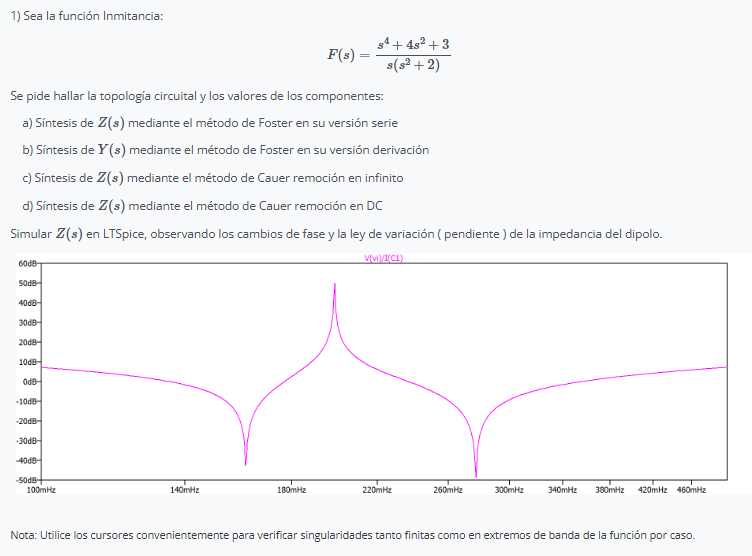

###Foster

* $k_0$
$$\lim_{s \to 0} F(s) = \frac{k_0}{s}$$
$$k_0 = \lim_{s \to 0} [s \cdot F(s)] = \lim_{s \to 0} \left( s \cdot \frac{s^4 + 4s^2 + 3}{s(s^2 + 2)} \right) = \lim_{s \to 0} \left( \frac{s^4 + 4s^2 + 3}{s^2 + 2} \right) = \frac{3}{2}$$

* $k_\infty$
$$k_\infty = \lim_{s \to \infty} \frac{F(s)}{s} = \lim_{s \to \infty} \frac{s^4 + 4s^2 + 3}{s^2(s^2 + 2)} = 1$$

* $k_1$
$$2k_1 = \lim_{s^2 \to -2} \left[ \frac{s^2 + 2}{s} \cdot \frac{s^4 + 4s^2 + 3}{s(s^2 + 2)} \right] = \lim_{s^2 \to -2} \left( \frac{s^4 + 4s^2 + 3}{s^2} \right) = \frac{(-2)^2 + 4(-2) + 3}{-2} = \frac{4 - 8 + 3}{-2} = \frac{1}{2}$$

### Expresión final:
$$F(s) = \frac{3}{2} \cdot \frac{1}{s} + s + \frac{\frac{1}{2}s}{s^2 + 2} = \frac{3}{2s} + s + \frac{s}{2(s^2 + 2)}$$

In [6]:
s = sp.symbols('s', complex=True)
FF = (s**4 + 4*s**2 + 3)/(s**3 + 2*s)

print_latex(f"F(s) = {sp.latex(FF)}")

<IPython.core.display.Math object>

#### Foster serie

<IPython.core.display.Math object>

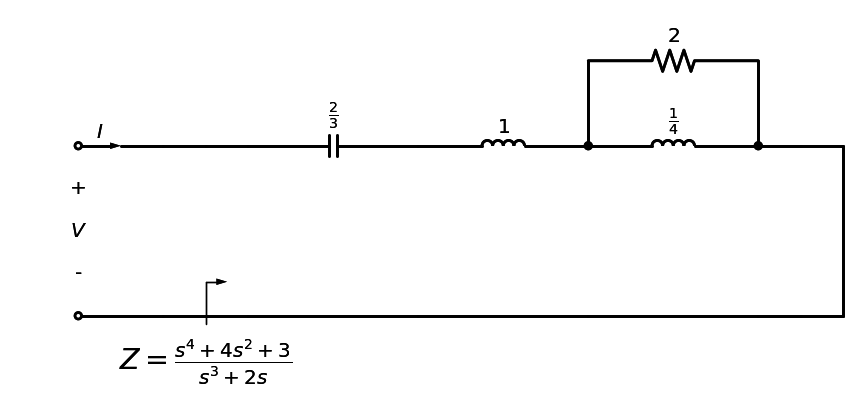

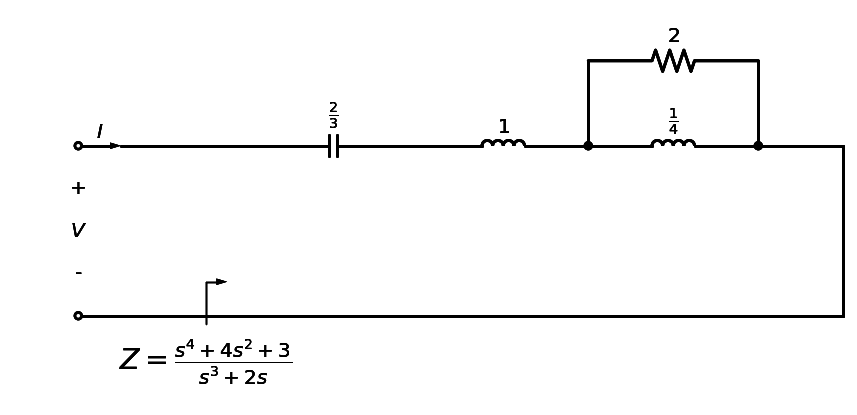

In [11]:

FF = (s**4 + 4*s**2 + 3)/(s**3 + 2*s)
k0, koo, ki_wi = foster(FF)

FF_foster = (1/k0)/s + koo*s + sum([2 * ki * s / (s**2 + wi**2) for ki, wi in ki_wi])


print_subtitle('Foster serie')
print_latex(f"Z(s) = F(s) = {sp.latex(FF)} = {sp.latex(FF_foster)}")

dibujar_foster_serie((1/k0), koo, ki_wi, z_exc=FF)

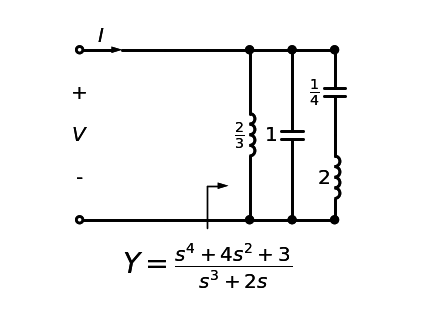

In [13]:
dibujar_foster_derivacion(1/k0, koo, ki_wi, y_exc = FF)

**Simulacion Spice**

Serie

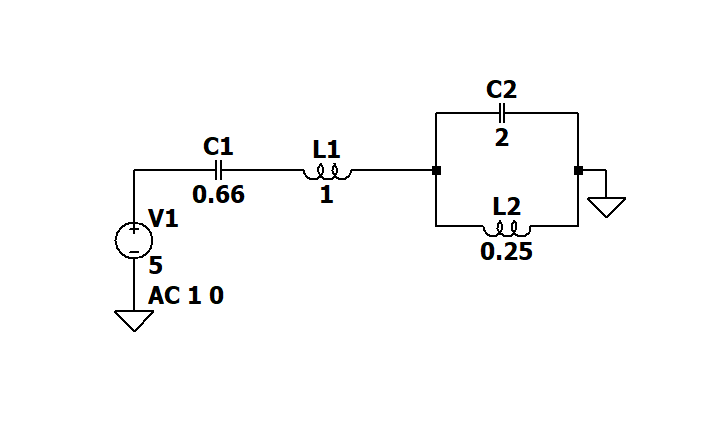

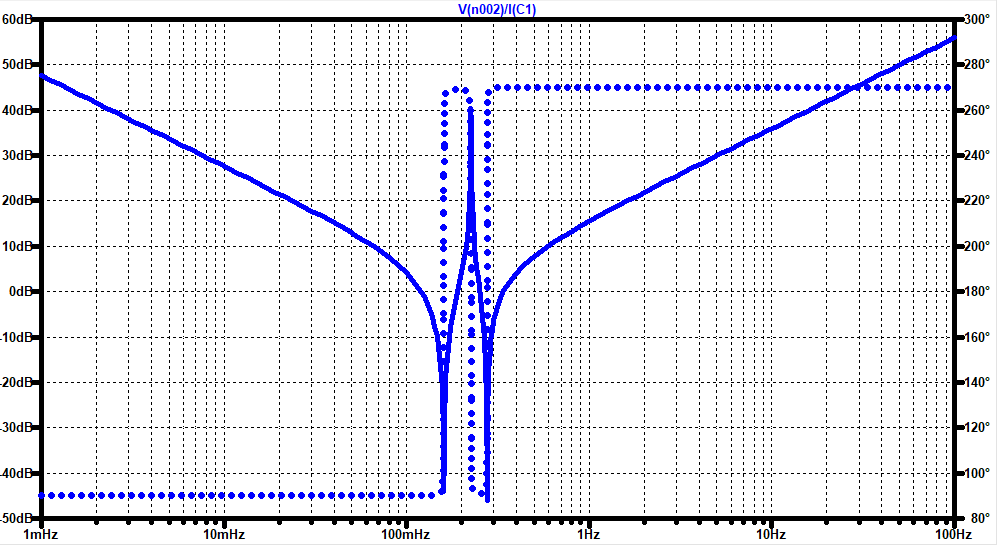

Buscamos Polos y ceros:

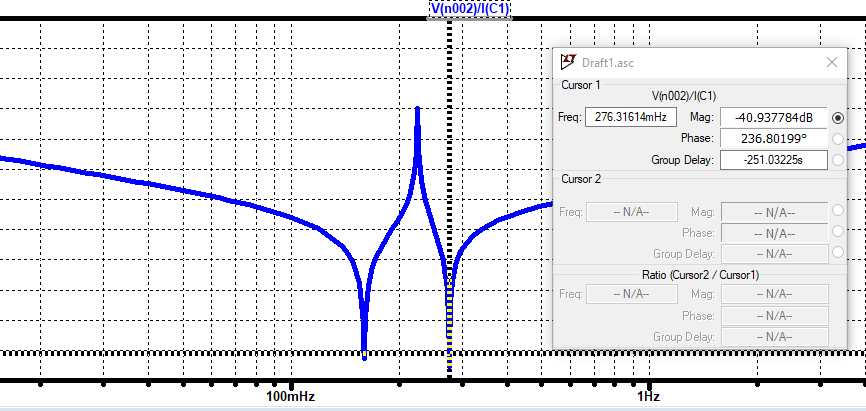

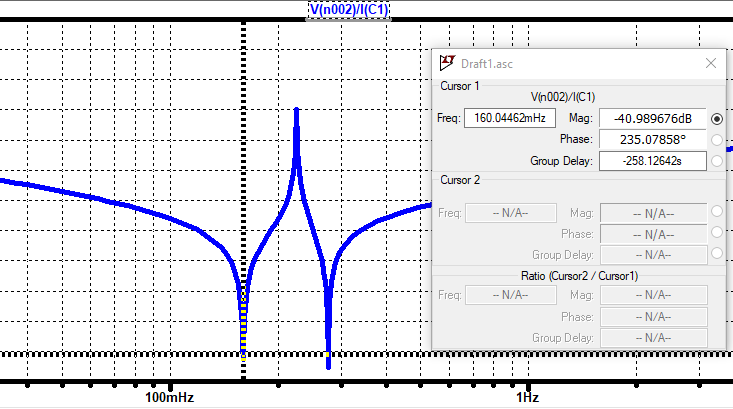

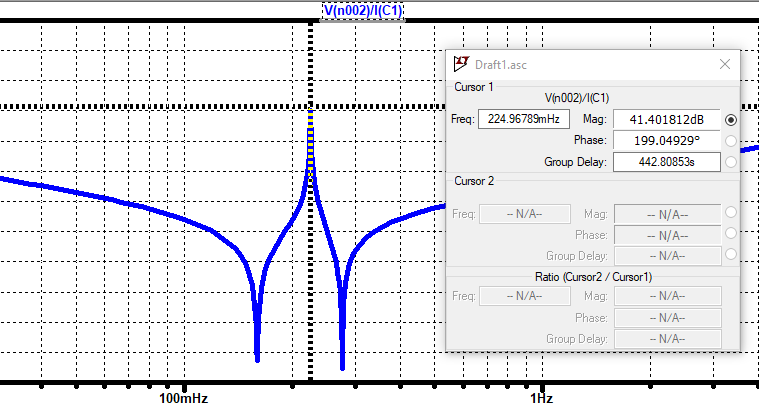

Notese:

$$276mHz=\sqrt{3}r/s$$
$$16mHz=1r/s$$
$$224mHz=\sqrt{2}$$

Paralelo

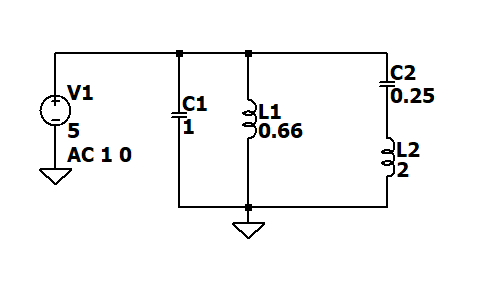

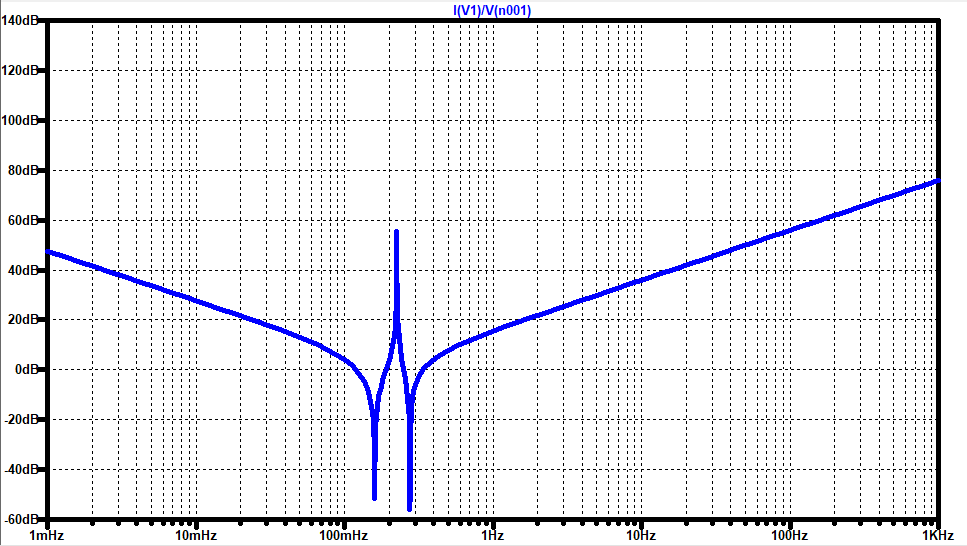

En este Caso, se ve que la admitancia tiene la misma respuesta que la impedancia del serie.

###Cauer

$$F(s) = \frac{s^4 + 4s^2 + 3}{s^3 + 2s}$$

$$\begin{array}{l|l r}
s^4 + 4s^2 + 3 & s^3 + 2s & \\
-(s^4 + 2s^2) & s & \longrightarrow z_1 = s \\
\hline
2s^2 + 3 & \frac{1}{2}s & \longrightarrow y_2 = \frac{1}{2}s \\
-(2s^2 + 0) & & \\
\hline
\frac{1}{2}s & 4s & \longrightarrow z_3 = 4s \\
-(\frac{1}{2}s) & & \\
\hline
3 & \frac{1}{6}s & \longrightarrow y_4 = \frac{1}{6}s \\
-(3) & & \\
\hline
0 & &
\end{array}$$

<IPython.core.display.Math object>

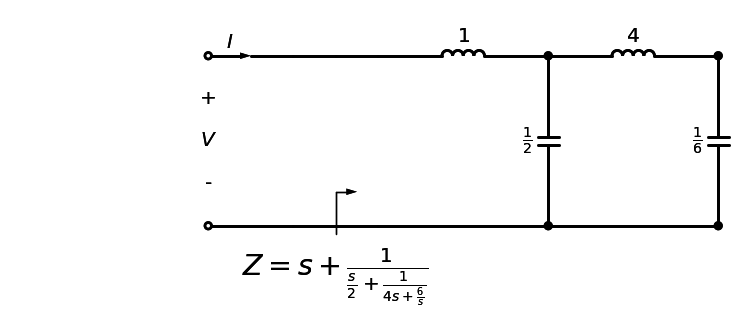

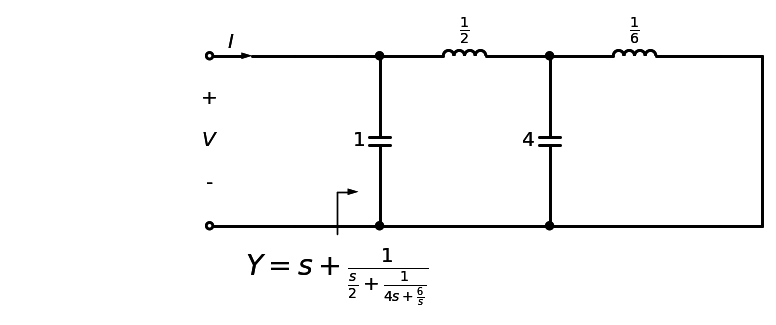

In [17]:
# Síntesis Cauer en infinito (Cauer 1)
koo, F_cauer_oo, rem = cauer_LC(FF, remover_en_inf=True)

# Imprimir la igualdad completa formateada
print_latex(f"F(s) = {sp.latex(FF)} = {sp.latex(F_cauer_oo)}")

dibujar_cauer_LC(koo, z_exc = F_cauer_oo)

# Tratamos a nuestra función inmitancia como una Y
dibujar_cauer_LC(koo, y_exc = F_cauer_oo)

**Simulacion Spice**

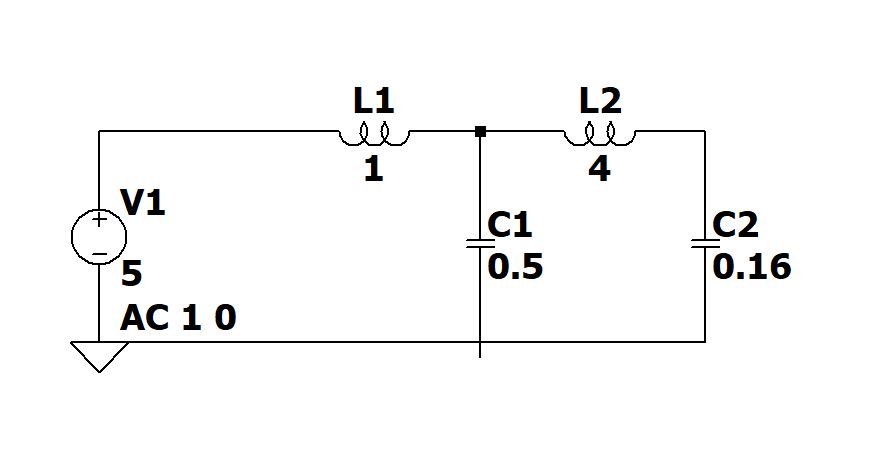

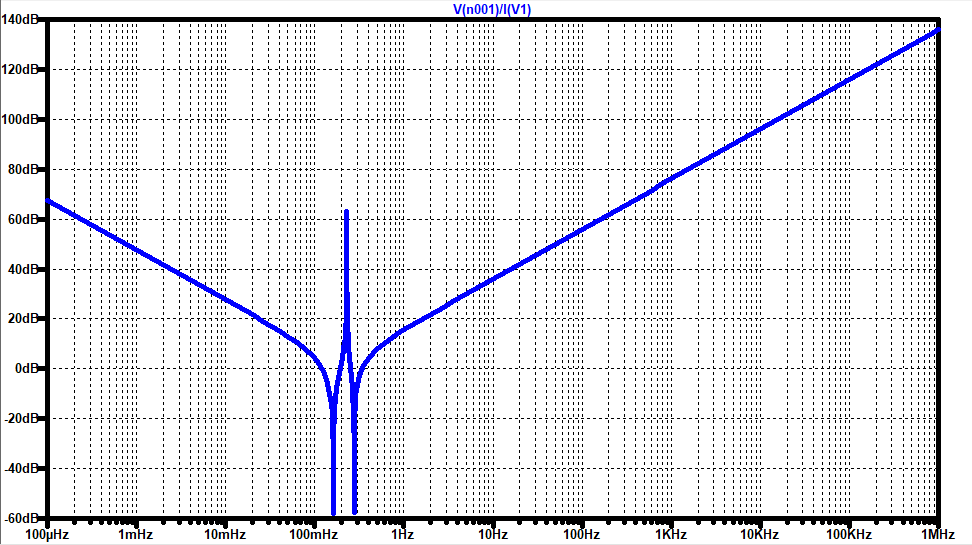

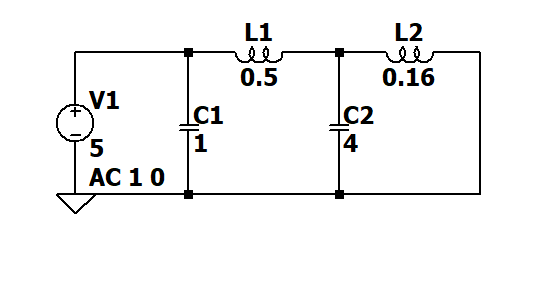

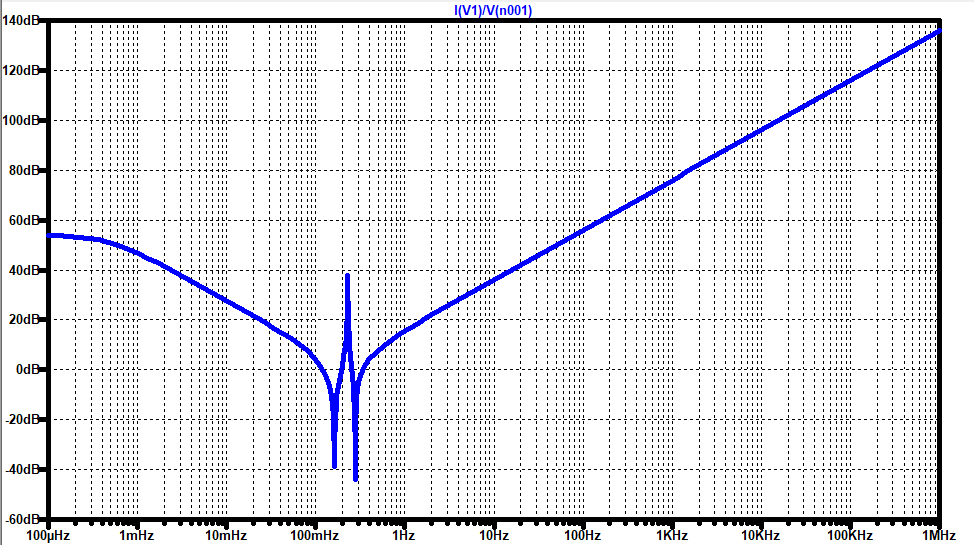

Se puede ver que la inmitancia es igual que en la ampliacion de foster.

##2

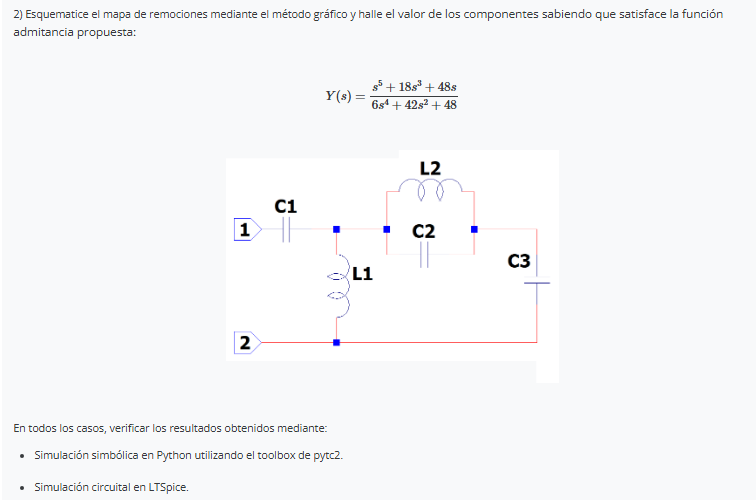


$$Z(s) = \frac{6s^4 + 42s^2 + 48}{s^5 + 18s^3 + 48s}$$


$$Z_2(s) = Z(s) - Z_1(s) = \frac{6s^4 + 42s^2 + 48}{s(s^4 + 18s^2 + 48)} - \frac{k_0}{s}$$

$$k_0 = \lim_{s \to 0} [s \cdot Z(s)] = \frac{48}{48} = 1 \implies Z_1(s) = \frac{1}{s} \quad (C_1 = 1\,\text{F})$$

---

$$Y_2(s) = \frac{1}{Z_2(s)} = \frac{s^4 + 18s^2 + 48}{5s^3 + 24s}$$


$$Y_4(s) = Y_2(s) - Y_3(s) = \frac{s^4 + 18s^2 + 48}{5s^3 + 24s} - \frac{1}{s L_1}$$

---
$$k_0' = \lim_{s \to 0} [s \cdot Y_2(s)] = \frac{48}{24} = 2 \implies \frac{1}{L_1} = 2 \implies L_1 = \frac{1}{2}\,\text{H}$$


$$Y_4(s) = \frac{s^4 + 18s^2 + 48}{5s^3 + 24s} - \frac{2}{s} = \frac{s^4 + 18s^2 + 48 - 2(5s^2 + 24)}{5s^3 + 24s} = \frac{s^4 + 8s^2}{5s^3 + 24s} = \frac{s^2 + 8}{5s^2 + 24}$$


$$Z_4(s) = \frac{5s^2 + 24}{s^3 + 8s} = \frac{5s^2 + 24}{s(s^2 + 8)}$$


$$2k_1 = \lim_{s^2 \to -8} \left[ \frac{s^2 + 8}{s} \cdot \frac{5s^2 + 24}{s(s^2 + 8)} \right] = \lim_{s^2 \to -8} \left( \frac{5s^2 + 24}{s^2} \right) = \frac{5(-8) + 24}{-8} = \frac{-16}{-8} = 2$$

$$Z_5(s) = \frac{2s}{s^2 + 8} = \frac{1}{\frac{s^2 + 8}{2s}} = \frac{1}{\frac{s}{2} + \frac{4}{s}} \implies L_2 = \frac{1}{4}\,\text{H}, \quad C_2 = \frac{1}{2}\,\text{F}$$

---
$$Z_6(s) = Z_4(s) - Z_5(s) = \frac{5s^2 + 24}{s(s^2 + 8)} - \frac{2s}{s^2 + 8} = \frac{5s^2 + 24 - 2s^2}{s(s^2 + 8)} = \frac{3s^2 + 24}{s(s^2 + 8)} = \frac{3(s^2 + 8)}{s(s^2 + 8)} = \frac{3}{s}$$

$$(C_3 = \frac{1}{3}\,\text{F})$$

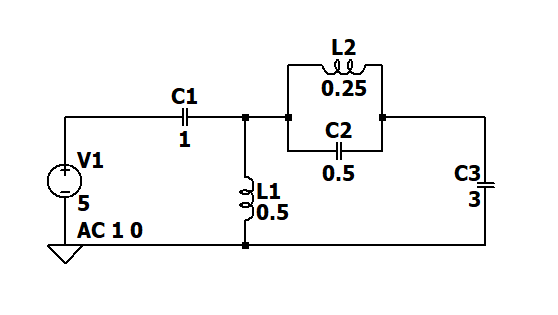

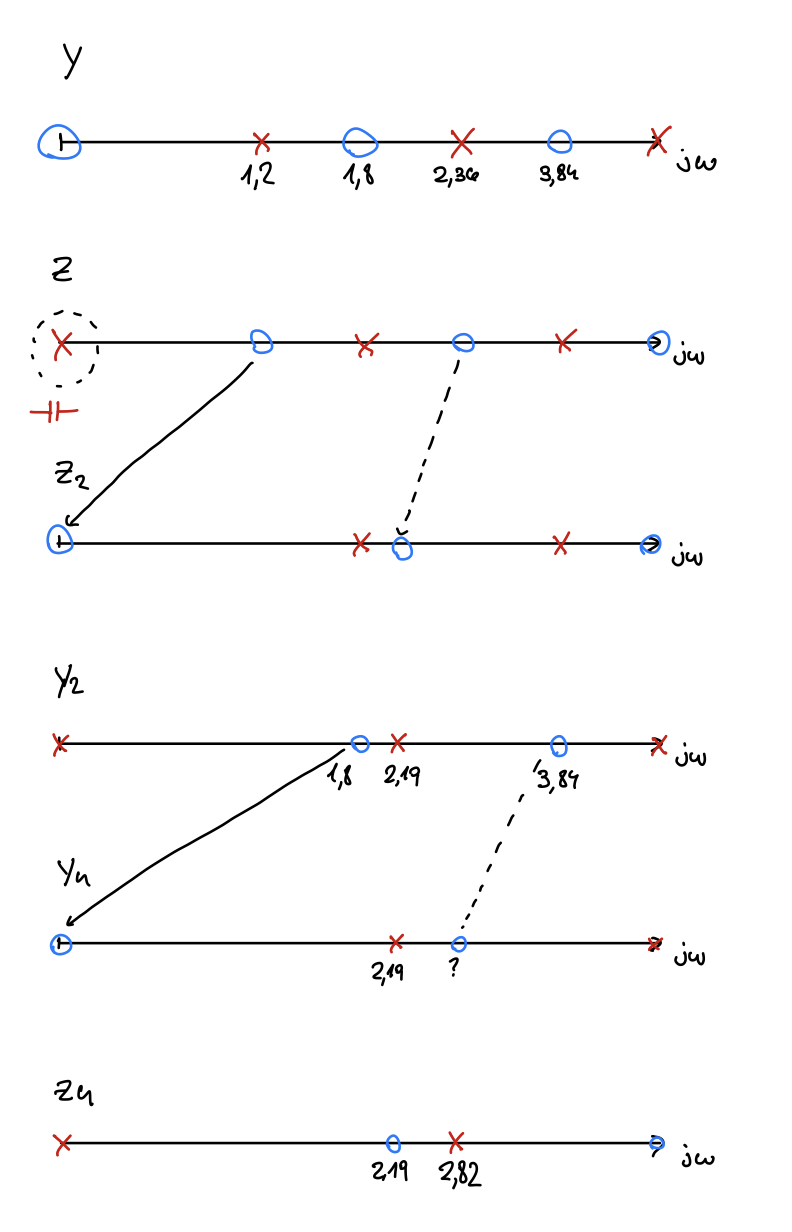

Simulacion Spice

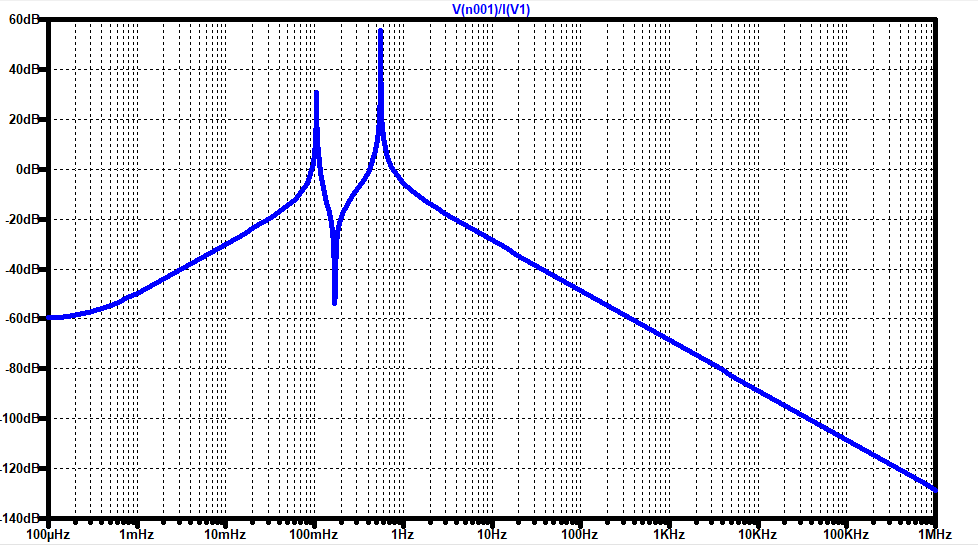